In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/COCO-conversion-script.py
/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/annotations_coco.json
/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/README.md
/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/YOLO-conversion-script.py
/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/labels/vlcsnap-2025-02-19-14h18m48s452.txt
/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/labels/vlcsnap-2025-02-19-14h21m29s062.txt
/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/labels/vlcsnap_2025-03-16-15h14m35s770.txt
/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/labels/vlcsnap-2025-02-18-23h25m45s670.txt
/kaggle/

In [4]:
import os

base = "/kaggle/input/datasets/lorenzoarcioni"

dataset_path = os.path.join(
    base,
    os.listdir(base)[0]
)

print("Dataset path:", repr(dataset_path))

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue

    print(f"\n📁 {root}")
    for file in files[:8]:
        print("  📄", file)

Dataset path: '/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes'

📁 /kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes

📁 /kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data
  📄 COCO-conversion-script.py
  📄 annotations_coco.json
  📄 README.md
  📄 YOLO-conversion-script.py

📁 /kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/labels
  📄 vlcsnap-2025-02-19-14h18m48s452.txt
  📄 vlcsnap-2025-02-19-14h21m29s062.txt
  📄 vlcsnap_2025-03-16-15h14m35s770.txt
  📄 vlcsnap-2025-02-18-23h25m45s670.txt
  📄 vlcsnap-2025-02-19-17h09m41s152.txt
  📄 vlcsnap-2025-02-26-20h36m21s506.txt
  📄 vlcsnap-2025-02-19-17h09m37s477.txt
  📄 vlcsnap-2025-02-19-15h11m45s542.txt

📁 /kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data/images
  📄 vlcsnap-2025-02-19-15h10m43s692.jpg
  📄 vlcsnap-2025-02-18-23h30m34s296.jpg
  📄 vlcs

In [5]:
import os
import json
from collections import Counter

data_path = dataset_path + "/data"
images_path = os.path.join(data_path, "images")
labels_path = os.path.join(data_path, "labels-YOLO")

images = [
    f for f in os.listdir(images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]
labels = [f for f in os.listdir(labels_path) if f.endswith(".txt")]

print("Number of images:", len(images))
print("Number of YOLO label files:", len(labels))

with open(os.path.join(data_path, "annotations_coco.json"), "r") as f:
    coco = json.load(f)

print("\nCOCO categories:")
for category in coco.get("categories", []):
    print(category["id"], "-", category["name"])

print("\nSample YOLO labels:")
for filename in labels[:3]:
    with open(os.path.join(labels_path, filename), "r") as f:
        print(filename, "=>", f.readline().strip()[:150])

Number of images: 2009
Number of YOLO label files: 2009

COCO categories:
0 - pothole
1 - crack
2 - manhole

Sample YOLO labels:
vlcsnap-2025-02-19-14h18m48s452.txt => 2 0.372656 0.575000 0.060938 0.033334
vlcsnap-2025-02-19-14h21m29s062.txt => 2 0.309375 0.654167 0.093750 0.052778
vlcsnap_2025-03-16-15h14m35s770.txt => 1 0.324219 0.723611 0.082812 0.102778


In [6]:
import os
import random
import shutil
import yaml
from pathlib import Path

# Dataset paths
data_path = Path(dataset_path) / "data"
images_path = data_path / "images"
labels_path = data_path / "labels-YOLO"

# Reproducible split
random.seed(42)

image_files = sorted([
    f for f in images_path.iterdir()
    if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

random.shuffle(image_files)

n = len(image_files)
n_train = int(n * 0.70)
n_val = int(n * 0.20)

splits = {
    "train": image_files[:n_train],
    "val": image_files[n_train:n_train + n_val],
    "test": image_files[n_train + n_val:]
}

# Create dataset folders
output_path = Path("/kaggle/working/road_damage_yolo")

for split, files in splits.items():
    image_out = output_path / "images" / split
    label_out = output_path / "labels" / split
    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)

    for image_file in files:
        label_file = labels_path / f"{image_file.stem}.txt"

        shutil.copy2(image_file, image_out / image_file.name)

        if label_file.exists():
            shutil.copy2(label_file, label_out / label_file.name)
        else:
            (label_out / f"{image_file.stem}.txt").touch()

# Create YOLO config
config = {
    "path": str(output_path),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "pothole",
        1: "crack",
        2: "manhole"
    }
}

yaml_path = output_path / "data.yaml"
with open(yaml_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Dataset preparation completed!")
print("Train:", len(splits["train"]))
print("Validation:", len(splits["val"]))
print("Test:", len(splits["test"]))
print("Config:", yaml_path)

Dataset preparation completed!
Train: 1406
Validation: 401
Test: 202
Config: /kaggle/working/road_damage_yolo/data.yaml


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available — enable it from Notebook Settings.")

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [2]:
%pip install -q -U ultralytics

import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0))

from ultralytics import YOLO

for model_name in ["yolov8n.pt", "yolo11n.pt", "yolo12n.pt"]:
    try:
        model = YOLO(model_name)
        print(f"{model_name}: supported")
        del model
    except Exception as e:
        print(f"{model_name}: unavailable - {e}")

Note: you may need to restart the kernel to use updated packages.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.191
GPU: Tesla T4
yolov8n.pt: supported
yolo11n.pt: supported
yolo12n.pt: supported


In [6]:
import os, random, yaml
from pathlib import Path

src = Path("/kaggle/input/datasets/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes/data")
out = Path("/kaggle/working/road_damage_yolo")

images = sorted((src / "images").glob("*"))
images = [p for p in images if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]

random.Random(42).shuffle(images)
a, b = int(len(images)*0.7), int(len(images)*0.9)
splits = {"train": images[:a], "val": images[a:b], "test": images[b:]}

for split, files in splits.items():
    for folder in ["images", "labels"]:
        (out / folder / split).mkdir(parents=True, exist_ok=True)
    for img in files:
        dest_img = out / "images" / split / img.name
        dest_label = out / "labels" / split / f"{img.stem}.txt"
        if not dest_img.exists():
            dest_img.symlink_to(img)
        label = src / "labels-YOLO" / f"{img.stem}.txt"
        if not dest_label.exists():
            if label.exists():
                dest_label.symlink_to(label)
            else:
                dest_label.touch()

config = {
    "path": str(out),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "pothole", 1: "crack", 2: "manhole"}
}
with open(out / "data.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Ready:", (out / "data.yaml").exists())
print("Train / Val / Test:", *(len(v) for v in splits.values()))

Ready: True
Train / Val / Test: 1406 402 201


In [7]:

import time
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

DATA_YAML = "/kaggle/working/road_damage_yolo/data.yaml"
RUNS_DIR = "/kaggle/working/road_damage_runs"

models = ["yolov8n.pt", "yolo11n.pt", "yolo12n.pt"]
results = []

for model_name in models:
    run_name = model_name.replace(".pt", "_baseline")
    print(f"\nTraining {model_name}...")

    start = time.time()

    model = YOLO(model_name)
    model.train(
        data=DATA_YAML,
        epochs=30,
        imgsz=640,
        batch=16,
        device=0,
        workers=2,
        seed=42,
        patience=8,
        project=RUNS_DIR,
        name=run_name,
        exist_ok=True,
        plots=True,
        verbose=False
    )

    training_minutes = (time.time() - start) / 60
    best_path = Path(RUNS_DIR) / run_name / "weights" / "best.pt"

    best_model = YOLO(str(best_path))
    metrics = best_model.val(
        data=DATA_YAML,
        split="val",
        imgsz=640,
        batch=16,
        device=0,
        plots=False,
        verbose=False
    )

    speed_ms = sum(metrics.speed.values())

    results.append({
        "Model": model_name,
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4),
        "Precision": round(metrics.box.mp, 4),
        "Recall": round(metrics.box.mr, 4),
        "Speed (ms/image)": round(speed_ms, 2),
        "Approx FPS": round(1000 / speed_ms, 2) if speed_ms else 0,
        "Size (MB)": round(best_path.stat().st_size / 1024**2, 2),
        "Training (min)": round(training_minutes, 2)
    })

    print(f"{model_name} completed.")
    del model, best_model, metrics

display(pd.DataFrame(results))



Training yolov8n.pt...
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_baseline, nbs=6

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      2.07G      2.336      2.512      1.765         43        640: 100% ━━━━━━━━━━━━ 88/88 10.0it/s 8.8s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 7.8it/s 1.7s0.1s
                   all        402        995      0.283      0.287      0.199      0.075

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.07G      2.298      2.425       1.76         71        640: 100% ━━━━━━━━━━━━ 88/88 9.8it/s 9.0s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 7.8it/s 1.7s0.1s
                   all        402        995      0.313      0.272      0.223     0.0859

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      2.07G      2.293      2.341       1.75         74        640: 100% ━━━━━━━━━━━━ 88/88 9.7it/s 9.1s0.1ss
                 Class     Images  Inst

,Model,mAP50,mAP50-95,Precision,Recall,Speed (ms/image),Approx FPS,Size (MB),Training (min)
0,yolov8n.pt,0.4594,0.1971,0.5082,0.4844,3.71,269.45,6.18,5.87
1,yolo11n.pt,0.4487,0.1891,0.5330,0.4224,3.74,267.52,5.23,6.74
2,yolo12n.pt,0.4629,0.1964,0.4967,0.4854,4.31,231.97,5.28,9.02


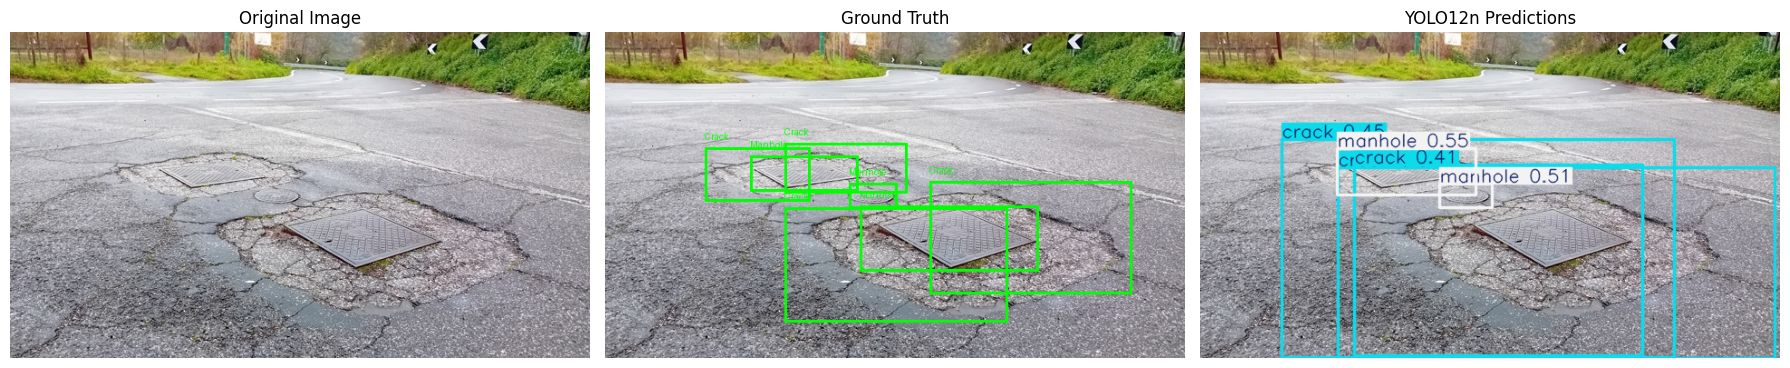

Images saved to: /kaggle/working/road_damage_visuals
Selected test image: 20250219_164838.jpg
Saved files:
01_original.jpg
02_ground_truth.jpg
03_yolo12n_predictions.jpg


In [9]:

from pathlib import Path
from PIL import Image, ImageDraw
from ultralytics import YOLO
import matplotlib.pyplot as plt

# Paths
BASE = Path("/kaggle/working/road_damage_yolo")
OUT = Path("/kaggle/working/road_damage_visuals")
OUT.mkdir(parents=True, exist_ok=True)

# Load the trained YOLO12n model
model = YOLO(
    "/kaggle/working/road_damage_runs/yolo12n_baseline/weights/best.pt"
)

# Choose a test image that has annotations
image_files = sorted((BASE / "images/test").glob("*"))
image_path = next(
    p for p in image_files
    if (BASE / "labels/test" / f"{p.stem}.txt").exists()
    and (BASE / "labels/test" / f"{p.stem}.txt").stat().st_size > 0
)

original = Image.open(image_path).convert("RGB")
w, h = original.size

# 1. Save original image
original.save(OUT / "01_original.jpg")

# 2. Draw Ground Truth boxes
gt_image = original.copy()
draw = ImageDraw.Draw(gt_image)
class_names = {0: "Pothole", 1: "Crack", 2: "Manhole"}

label_path = BASE / "labels/test" / f"{image_path.stem}.txt"

for line in label_path.read_text().splitlines():
    values = list(map(float, line.split()))
    cls, xc, yc, bw, bh = values[:5]

    x1 = int((xc - bw / 2) * w)
    y1 = int((yc - bh / 2) * h)
    x2 = int((xc + bw / 2) * w)
    y2 = int((yc + bh / 2) * h)

    draw.rectangle((x1, y1, x2, y2), outline="lime", width=3)
    draw.text((x1, max(0, y1 - 18)), class_names[int(cls)], fill="lime")

gt_image.save(OUT / "02_ground_truth.jpg")

# 3. Draw model predictions
prediction = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.25,
    device=0,
    verbose=False
)[0]

pred_image = Image.fromarray(prediction.plot()[..., ::-1])
pred_image.save(OUT / "03_yolo12n_predictions.jpg")

# Display all three images
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, img, title in zip(
    axes,
    [original, gt_image, pred_image],
    ["Original Image", "Ground Truth", "YOLO12n Predictions"]
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Images saved to:", OUT)
print("Selected test image:", image_path.name)
print("Saved files:")
for p in sorted(OUT.glob("*.jpg")):
    print(p.name)


In [11]:

from ultralytics import YOLO
from pathlib import Path
import pandas as pd
import time

DATA_YAML = "/kaggle/working/road_damage_yolo/data.yaml"
BASELINE = "/kaggle/working/road_damage_runs/yolo12n_baseline/weights/best.pt"
RUNS_DIR = "/kaggle/working/road_damage_runs"

# Hyperparameter tuning experiment
model = YOLO(BASELINE)

start = time.time()

model.train(
    data=DATA_YAML,
    epochs=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    seed=42,
    patience=5,
    lr0=0.001,
    project=RUNS_DIR,
    name="yolo12n_tuning_lr001",
    exist_ok=True,
    plots=True,
    verbose=False
)

print(f"Tuning training time: {(time.time() - start) / 60:.2f} minutes")

# Validate tuned model
TUNED_PATH = f"{RUNS_DIR}/yolo12n_tuning_lr001/weights/best.pt"
tuned = YOLO(TUNED_PATH)

metrics = tuned.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    plots=False,
    verbose=False
)

print("\nTUNED MODEL RESULTS")
print("mAP50:", round(metrics.box.map50, 4))
print("mAP50-95:", round(metrics.box.map, 4))
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))


Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/road_damage_runs/yolo12n_baseline/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0

In [12]:

from ultralytics import YOLO
from pathlib import Path
import time

DATA_YAML = "/kaggle/working/road_damage_yolo/data.yaml"
BASELINE = "/kaggle/working/road_damage_runs/yolo12n_baseline/weights/best.pt"
RUNS_DIR = "/kaggle/working/road_damage_runs"

# New tuning experiment
model = YOLO(BASELINE)
start = time.time()

model.train(
    data=DATA_YAML,
    epochs=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    seed=42,
    patience=5,
    lr0=0.0005,
    lrf=0.01,
    weight_decay=0.0005,
    project=RUNS_DIR,
    name="yolo12n_tuning_lr0005",
    exist_ok=True,
    plots=True,
    verbose=False
)

print(f"Training time: {(time.time() - start) / 60:.2f} minutes")

# Validate tuned model
best_path = Path(RUNS_DIR) / "yolo12n_tuning_lr0005/weights/best.pt"
tuned = YOLO(str(best_path))

metrics = tuned.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    batch=16,
    device=0,
    plots=False,
    verbose=False
)

print("\nTUNED RESULTS")
print("mAP50:", round(metrics.box.map50, 4))
print("mAP50-95:", round(metrics.box.map, 4))
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))


Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/road_damage_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/working/road_damage_runs/yolo12n_baseline/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=

In [16]:
from ultralytics import YOLO

model = YOLO(
    "/kaggle/working/road_damage_runs/yolo12n_baseline/weights/best.pt"
)

metrics = model.val(
    data="/kaggle/working/road_damage_yolo/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    verbose=False
)

print("\nFINAL TEST RESULTS")
print("mAP50:", round(metrics.box.map50, 4))
print("mAP50-95:", round(metrics.box.map, 4))
print("Precision:", round(metrics.box.mp, 4))
print("Recall:", round(metrics.box.mr, 4))

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv12n summary (fused): 160 layers, 2,572,113 parameters, 0 gradients, 7.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.3±0.1 ms, read: 0.8±0.3 MB/s, size: 101.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/working/road_damage_yolo/labels/test... 25 images, 0 backgrounds, 0 corrupt: 12% ━─────────── 25/202 13.0it/s 1.9s<13.6srequirements: Ultralytics requirement ['pi-heif'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 294ms
Prepared 1 package in 55ms
Installed 1 package in 2ms
 + pi-heif==1.4.0

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

val: Scanning /kaggle/working/road_damage_yolo/labels/test... 201 images, 0 backgrounds, 1 corrupt:

In [17]:
from ultralytics import YOLO
from pathlib import Path
import numpy as np
import cv2

MODEL_PATH = "/kaggle/working/road_damage_runs/yolo12n_baseline/weights/best.pt"
DATA_DIR = Path("/kaggle/working/road_damage_yolo")
IMAGE_DIR = DATA_DIR / "images" / "test"
LABEL_DIR = DATA_DIR / "labels" / "test"

model = YOLO(MODEL_PATH)
ious = []

def box_iou_xyxy(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])
    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0.0

image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
)

for image_path in image_paths:
    image = cv2.imread(str(image_path))
    if image is None:
        continue

    label_path = LABEL_DIR / f"{image_path.stem}.txt"
    if not label_path.exists():
        continue

    height, width = image.shape[:2]
    gt_boxes = []

    for line in label_path.read_text().splitlines():
        values = line.split()
        if len(values) != 5:
            continue

        cls, xc, yc, bw, bh = map(float, values)
        gt_boxes.append((
            int(cls),
            [(xc - bw / 2) * width, (yc - bh / 2) * height,
             (xc + bw / 2) * width, (yc + bh / 2) * height]
        ))

    result = model.predict(
        source=image, imgsz=640, conf=0.25, iou=0.7, verbose=False
    )[0]

    pred_boxes = []
    if result.boxes is not None:
        for box in result.boxes:
            pred_boxes.append((
                int(box.cls.item()),
                box.xyxy[0].cpu().numpy().tolist()
            ))

    candidates = []
    for gi, (gt_cls, gt_box) in enumerate(gt_boxes):
        for pi, (pred_cls, pred_box) in enumerate(pred_boxes):
            if gt_cls == pred_cls:
                overlap = box_iou_xyxy(gt_box, pred_box)
                candidates.append((overlap, gi, pi))

    matched_gt, matched_pred = set(), set()

    for overlap, gi, pi in sorted(candidates, reverse=True):
        if gi not in matched_gt and pi not in matched_pred:
            matched_gt.add(gi)
            matched_pred.add(pi)
            ious.append(overlap)

if ious:
    print("Matched boxes:", len(ious))
    print("Mean IoU:", round(float(np.mean(ious)), 4))
    print("Mean IoU (%):", round(float(np.mean(ious)) * 100, 2))
else:
    print("No matching boxes found. Check the image and label paths.")

Matched boxes: 259
Mean IoU: 0.5941
Mean IoU (%): 59.41


In [18]:
from pathlib import Path
from ultralytics import YOLO
import time

RUNS_DIR = Path("/kaggle/working/road_damage_runs")
DATA_YAML = "/kaggle/working/road_damage_yolo/data.yaml"

models_info = [
    ("YOLOv8n", "yolov8n_baseline"),
    ("YOLO11n", "yolo11n_baseline"),
    ("YOLO12n", "yolo12n_baseline"),
]

results = []

for model_name, run_name in models_info:
    weights = RUNS_DIR / run_name / "weights" / "best.pt"

    if not weights.exists():
        print(f"Missing weights: {weights}")
        continue

    model = YOLO(str(weights))

    metrics = model.val(
        data=DATA_YAML,
        split="val",
        imgsz=640,
        batch=16,
        device=0,
        plots=False,
        verbose=False
    )

    inference_ms = metrics.speed["inference"]
    size_mb = weights.stat().st_size / (1024 ** 2)

    results.append({
        "Model": model_name,
        "mAP50": round(metrics.box.map50, 4),
        "mAP50-95": round(metrics.box.map, 4),
        "Precision": round(metrics.box.mp, 4),
        "Recall": round(metrics.box.mr, 4),
        "Inference_ms_image": round(inference_ms, 2),
        "Approx_FPS": round(1000 / inference_ms, 2) if inference_ms else None,
        "Model_Size_MB": round(size_mb, 2)
    })

import pandas as pd
comparison_df = pd.DataFrame(results)
display(comparison_df)

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2108.5±507.6 MB/s, size: 91.2 KB)
val: Scanning /kaggle/working/road_damage_yolo/labels/val.cache... 402 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 402/402 58.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 11.3it/s 2.3s0.1s
                   all        402        995      0.508      0.484      0.459      0.197
Speed: 0.5ms preprocess, 2.2ms inference, 0.0ms loss, 0.9ms postprocess per image
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1416.9±257.5 MB/s, size: 105.8 KB)
val: Scanning /kaggle/working/road_damage_yolo/labe

,Model,mAP50,mAP50-95,Precision,Recall,Inference_ms_image,Approx_FPS,Model_Size_MB
0,YOLOv8n,0.4594,0.1971,0.5082,0.4844,2.24,447.00,6.18
1,YOLO11n,0.4487,0.1891,0.5330,0.4224,2.04,489.47,5.23
2,YOLO12n,0.4629,0.1964,0.4967,0.4854,2.73,366.90,5.28


In [43]:
from pathlib import Path

project = Path("/kaggle/working/road_damage_flask")
templates = project / "templates"
templates.mkdir(parents=True, exist_ok=True)

app_code = r'''
from flask import Flask, render_template, request
from ultralytics import YOLO
from pathlib import Path
import cv2
import numpy as np
import uuid

app = Flask(__name__)

BASE_DIR = Path(__file__).resolve().parent
RESULTS_DIR = BASE_DIR / "static" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASET_IMAGES = Path(
    "/kaggle/input/datasets/lorenzoarcioni/"
    "road-damage-dataset-potholes-cracks-and-manholes/data/images"
)

model = YOLO(str(BASE_DIR / "best.pt"))
CLASS_NAMES = {0: "Pothole", 1: "Crack", 2: "Manhole"}

@app.route("/", methods=["GET", "POST"])
def index():
    result_image = None
    detections = []
    error = None
    selected_image = ""

    sample_images = sorted(
        p.name for p in DATASET_IMAGES.iterdir()
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".webp"}
    ) if DATASET_IMAGES.exists() else []

    if request.method == "POST":
        selected_image = request.form.get("sample_image", "")
        uploaded_file = request.files.get("image")
        image = None

        # Use a selected dataset image first; otherwise use an upload.
        if selected_image:
            if selected_image not in sample_images:
                error = "Invalid dataset image selection."
            else:
                image = cv2.imread(str(DATASET_IMAGES / selected_image))
        elif uploaded_file and uploaded_file.filename:
            image = cv2.imdecode(
                np.frombuffer(uploaded_file.read(), np.uint8),
                cv2.IMREAD_COLOR
            )
        else:
            error = "Choose a dataset image or upload your own."

        try:
            confidence = float(request.form.get("confidence", 0.25))
            confidence = max(0.1, min(0.9, confidence))
        except (ValueError, TypeError):
            confidence = 0.25

        if not error:
            if image is None:
                error = "Could not read this image."
            else:
                result = model.predict(
                    image, conf=confidence, imgsz=640, verbose=False
                )[0]

                output_name = f"{uuid.uuid4().hex}.jpg"
                cv2.imwrite(str(RESULTS_DIR / output_name), result.plot())
                result_image = "results/" + output_name

                if result.boxes is not None:
                    for box in result.boxes:
                        cls_id = int(box.cls.item())
                        detections.append({
                            "name": CLASS_NAMES.get(cls_id, str(cls_id)),
                            "confidence": round(float(box.conf.item()) * 100, 2)
                        })

    return render_template(
        "index.html",
        sample_images=sample_images,
        selected_image=selected_image,
        result_image=result_image,
        detections=detections,
        error=error
    )

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, debug=False)
'''

html_code = r'''
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <title>Road Damage Detection</title>
    <style>
        body { font-family: Arial, sans-serif; max-width: 900px; margin: 30px auto; padding: 0 16px; background: #f4f7f6; color: #20332d; }
        h1 { color: #176b52; }
        .panel { background: white; padding: 22px; border-radius: 12px; margin: 18px 0; }
        label { display: block; margin: 14px 0 6px; font-weight: bold; }
        select, input, button { width: 100%; padding: 10px; box-sizing: border-box; }
        button { margin-top: 18px; background: #176b52; color: white; border: 0; border-radius: 7px; cursor: pointer; }
        img { max-width: 100%; border-radius: 8px; margin-top: 12px; }
        .error { color: #b00020; }
        .hint { color: #586861; font-size: 14px; }
    </style>
</head>
<body>
    <h1>Road Damage Detection</h1>
    <p>Detect potholes, cracks, and manholes using the trained YOLO model.</p>

    <div class="panel">
        <form method="POST" enctype="multipart/form-data">
            <label for="sample_image">Choose an image from the dataset</label>
            <select name="sample_image" id="sample_image">
                <option value="">-- Or upload your own image below --</option>
                {% for image in sample_images %}
                <option value="{{ image }}" {% if selected_image == image %}selected{% endif %}>
                    {{ image }}
                </option>
                {% endfor %}
            </select>
            <p class="hint">{{ sample_images|length }} dataset images available.</p>

            <label for="image">Or upload an image from your device</label>
            <input type="file" name="image" id="image" accept="image/*">

            <label for="confidence">Confidence threshold (0.1–0.9)</label>
            <input type="number" id="confidence" name="confidence" min="0.1" max="0.9" step="0.05" value="0.25">

            <button type="submit">Detect Road Damage</button>
        </form>
    </div>

    {% if error %}
    <div class="panel error">{{ error }}</div>
    {% endif %}

    {% if result_image %}
    <div class="panel">
        <h2>Detection Result</h2>
        <img src="{{ url_for('static', filename=result_image) }}" alt="Predicted road damage">
        <h3>Detected Objects: {{ detections|length }}</h3>
        {% if detections %}
        <ul>
            {% for item in detections %}
            <li>{{ item.name }} — {{ item.confidence }}% confidence</li>
            {% endfor %}
        </ul>
        {% else %}
        <p>No objects detected at this confidence threshold.</p>
        {% endif %}
    </div>
    {% endif %}
</body>
</html>
'''

(project / "app.py").write_text(app_code, encoding="utf-8")
(templates / "index.html").write_text(html_code, encoding="utf-8")

print("Updated successfully:")
print(project / "app.py")
print(templates / "index.html")

Updated successfully:
/kaggle/working/road_damage_flask/app.py
/kaggle/working/road_damage_flask/templates/index.html


In [28]:
from pathlib import Path

requirements = """flask
ultralytics
opencv-python-headless
numpy
"""

Path("/kaggle/working/road_damage_flask/requirements.txt").write_text(requirements)

print(Path("/kaggle/working/road_damage_flask/requirements.txt").read_text())

flask
ultralytics
opencv-python-headless
numpy



In [29]:
%cd /kaggle/working/road_damage_flask

!pip -q install -r requirements.txt

print("Requirements installed successfully!")

/kaggle/working/road_damage_flask
Requirements installed successfully!


In [30]:
%cd /kaggle/working/road_damage_flask

!pip -q install -r requirements.txt

!python -c "import flask, cv2, ultralytics; print('All dependencies imported successfully')"

print("App file exists:", __import__("os").path.exists("app.py"))
print("Model file exists:", __import__("os").path.exists("best.pt"))

/kaggle/working/road_damage_flask
All dependencies imported successfully
App file exists: True
Model file exists: True


In [44]:
%cd /kaggle/working/road_damage_flask

!python -c "import subprocess, sys; subprocess.Popen([sys.executable, 'app.py'])"

print("Flask server started.")

/kaggle/working/road_damage_flask
Flask server started.


In [47]:
import subprocess
import time
import requests
from pathlib import Path

# Stop the previous Flask process if we started it in this notebook
try:
    flask_process.terminate()
    flask_process.wait(timeout=5)
except:
    pass

# Find and stop any process using port 5000
!fuser -k 5000/tcp

# Start the updated app
app_dir = Path("/kaggle/working/road_damage_flask")
flask_log = open("/kaggle/working/flask.log", "w")

flask_process = subprocess.Popen(
    ["python", str(app_dir / "app.py")],
    cwd=str(app_dir),
    stdout=flask_log,
    stderr=subprocess.STDOUT
)

time.sleep(8)

try:
    response = requests.get("http://127.0.0.1:5000", timeout=10)
    print("Flask status:", response.status_code)
    print("Updated app is running!")
except Exception as e:
    print("Error:", e)
    print(Path("/kaggle/working/flask.log").read_text())

Flask status: 200
Updated app is running!


In [48]:
from pycloudflared import try_cloudflare

tunnel = try_cloudflare(port=5000)
print(tunnel)

 * Running on https://neck-theory-bracelet-lawyers.trycloudflare.com
 * Traffic stats available on http://127.0.0.1:20241/metrics
Urls(tunnel='https://neck-theory-bracelet-lawyers.trycloudflare.com', metrics='http://127.0.0.1:20241/metrics', process=<Popen: returncode: None args: ['/usr/local/lib/python3.13/dist-packages/pyc...>)


In [38]:
!pip -q install pycloudflared